In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load, dump
import os
import tables
import pathlib
from IPython.display import display
from matplotlib.colors import Normalize
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde



import warnings
warnings.filterwarnings("ignore")
    
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

### Datasets

In [2]:
corrs = load('xgb_res/correlations.joblib')

In [3]:
proteomics = load('xgb_res/proteomics_matched.joblib')

In [4]:
tables.file._open_files.close_all()
p = pathlib.Path(r"xgb_res/xgb_all_results.h5")
print("exists:", p.exists(), "size:", p.stat().st_size, "bytes")
# Load all data from the HDF5 file
h5_file = 'xgb_res/xgb_all_results.h5'
eps = 1e-8

with pd.HDFStore(h5_file) as store:
    keys = store.keys()
    df_list = [store[key] for key in keys]
    combined_df = pd.concat(df_list, ignore_index=True)
print("Combined DataFrame shape:", combined_df.shape)


exists: True size: 94805704 bytes
Combined DataFrame shape: (1886697, 4)


In [5]:
# Non-finite overview (NaN / +Inf / -Inf) for combined_df

df = combined_df  # already loaded above
n_rows, n_cols = df.shape

# split columns
numeric_cols = df.select_dtypes(include=[np.number]).columns
non_numeric_cols = df.columns.difference(numeric_cols)

# per-column counts
nan_counts = df.isna().sum()

# ±Inf only make sense for numeric columns
if len(numeric_cols) > 0:
    posinf_counts_num = pd.Series(
        np.isposinf(df[numeric_cols].to_numpy()).sum(axis=0), index=numeric_cols, dtype="int64"
    )
    neginf_counts_num = pd.Series(
        np.isneginf(df[numeric_cols].to_numpy()).sum(axis=0), index=numeric_cols, dtype="int64"
    )
else:
    posinf_counts_num = pd.Series(dtype="int64")
    neginf_counts_num = pd.Series(dtype="int64")

# align to all columns (0 for non-numeric)
posinf_counts = pd.Series(0, index=df.columns, dtype="int64")
neginf_counts = pd.Series(0, index=df.columns, dtype="int64")
posinf_counts.loc[posinf_counts_num.index] = posinf_counts_num
neginf_counts.loc[neginf_counts_num.index] = neginf_counts_num

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_nan": nan_counts.astype("int64"),
    "n_posinf": posinf_counts,
    "n_neginf": neginf_counts,
})
summary["n_inf"] = summary["n_posinf"] + summary["n_neginf"]
summary["n_nonfinite"] = summary["n_nan"] + summary["n_inf"]
summary["pct_nonfinite"] = (summary["n_nonfinite"] / max(n_rows, 1)) * 100

# row-level stats
nan_any_row = df.isna().any(axis=1).to_numpy()

if len(numeric_cols) > 0:
    inf_mask = np.isinf(df[numeric_cols].to_numpy())
    inf_any_row = inf_mask.any(axis=1)
else:
    inf_any_row = np.zeros(n_rows, dtype=bool)

nonfinite_any_row = nan_any_row | inf_any_row

print(f"Rows: {n_rows}  |  Columns: {n_cols} (numeric: {len(numeric_cols)}, non-numeric: {len(non_numeric_cols)})")
print(f"Rows with any NaN: {int(nan_any_row.sum())}")
print(f"Rows with any ±Inf (numeric only): {int(inf_any_row.sum())}")
print(f"Rows with any non-finite (NaN or ±Inf): {int(nonfinite_any_row.sum())}\n")

# show columns with most issues first
summary_sorted = summary.sort_values("n_nonfinite", ascending=False)

# pretty display
display(
    summary_sorted.style
        .format({"pct_nonfinite": "{:.2f}%", "n_nan": "{:d}", "n_posinf": "{:d}", "n_neginf": "{:d}", "n_inf": "{:d}", "n_nonfinite": "{:d}"})
        .bar(subset=["n_nonfinite"], color="#FFA07A")
        .bar(subset=["n_nan"], color="#FFDAB9")
        .bar(subset=["n_inf"], color="#FFC0CB")
)

# optional: quick list of the top 10 worst columns
print("\nTop 10 columns by non-finite values:")
display(summary_sorted.head(10)[["dtype","n_nonfinite","n_nan","n_inf","pct_nonfinite"]])


Rows: 1886697  |  Columns: 4 (numeric: 2, non-numeric: 2)
Rows with any NaN: 381546
Rows with any ±Inf (numeric only): 0
Rows with any non-finite (NaN or ±Inf): 381546



,dtype,n_nan,n_posinf,n_neginf,n_inf,n_nonfinite,pct_nonfinite
predicted,float64,381546,0,0,0,381546,20.22%
protein,object,0,0,0,0,0,0.00%
LOO sample,object,0,0,0,0,0,0.00%
true,float64,0,0,0,0,0,0.00%



Top 10 columns by non-finite values:


,dtype,n_nonfinite,n_nan,n_inf,pct_nonfinite
predicted,float64,381546,381546,0,20.222961
protein,object,0,0,0,0.000000
LOO sample,object,0,0,0,0.000000
true,float64,0,0,0,0.000000


In [6]:

df = combined_df.copy()

# choose the sample column
sample_col = 'LOO sample' if 'LOO sample' in df.columns else 'sample'

# keep only numeric/finite true & predicted
df['true'] = pd.to_numeric(df['true'], errors='coerce')
df['predicted'] = pd.to_numeric(df['predicted'], errors='coerce')
df = df.replace([np.inf, -np.inf], np.nan)

# mask of rows with finite true & predicted
row_ok = df[['true', 'predicted']].notna().all(axis=1)

# A) proteins present after dropping all non-finite rows (≥1 valid row remains)
n_proteins_total = df['protein'].nunique()
n_proteins_after_drop = df.loc[row_ok, 'protein'].nunique()

print(f"Unique proteins (total): {n_proteins_total}")
print(f"Unique proteins with at least one valid row after removing NaNs/±Inf: {n_proteins_after_drop}")

# B) proteins complete across *all* their rows (no NaN/±Inf anywhere)
protein_complete = (
    df.groupby('protein')[['true', 'predicted']]
      .apply(lambda g: g.notna().all().all())
)
n_proteins_complete = int(protein_complete.sum())
print(f"Proteins complete across all rows (no NaN/±Inf in true/predicted): {n_proteins_complete}")

# C) per-sample: how many proteins remain after removing NaNs/±Inf (counts of valid rows)
per_sample_counts = (
    df.groupby(sample_col)
      .apply(lambda g: g[['true','predicted']].notna().all(axis=1).sum())
      .reset_index(name='n_proteins_remaining')
)

print("\nPer-sample proteins remaining (first 10 rows):")
display(per_sample_counts.head(10))

print("\nPer-sample summary:")
print(
    per_sample_counts['n_proteins_remaining']
      .agg(['min','median','max'])
      .rename({'min':'min', 'median':'median', 'max':'max'})
      .to_string()
)


Unique proteins (total): 5113
Unique proteins with at least one valid row after removing NaNs/±Inf: 4079
Proteins complete across all rows (no NaN/±Inf in true/predicted): 4079

Per-sample proteins remaining (first 10 rows):


,LOO sample,n_proteins_remaining
0,22RV1_PROSTATE,4079
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079
2,769P_KIDNEY,4079
3,786O_KIDNEY,4079
4,8305C_THYROID,4079
5,8505C_THYROID,4079
6,A101D_SKIN,4079
7,A172_CENTRAL_NERVOUS_SYSTEM,4079
8,A204_SOFT_TISSUE,4079
9,A2058_SKIN,4079



Per-sample summary:
min       4079.0
median    4079.0
max       4079.0


In [7]:
# Clean combined_df by removing entire proteins that contain any NaN/±Inf in true/predicted
df = combined_df.copy()

# 1) Coerce to numeric and turn ±Inf into NaN
df["true"] = pd.to_numeric(df["true"], errors="coerce")
df["predicted"] = pd.to_numeric(df["predicted"], errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan)

# 2) Which proteins are COMPLETE (no NaN in any of their rows for true/predicted)?
protein_complete = (
    df.groupby("protein")[["true", "predicted"]]
      .apply(lambda g: g.notna().all().all())
)
kept_proteins = protein_complete[protein_complete].index

# 3) Filter to the cleaned dataset
combined_df_clean = df[df["protein"].isin(kept_proteins)].copy()

# 4) New NaN/Inf overview (should be zero for true/predicted)
n_rows_before = len(df)
n_rows_after  = len(combined_df_clean)
n_proteins_before = df["protein"].nunique()
n_proteins_after  = combined_df_clean["protein"].nunique()

nan_true_before = df["true"].isna().sum()
nan_pred_before = df["predicted"].isna().sum()
nan_true_after  = combined_df_clean["true"].isna().sum()
nan_pred_after  = combined_df_clean["predicted"].isna().sum()

print(f"Rows before:  {n_rows_before:,}   | proteins before:  {n_proteins_before:,}")
print(f"Rows after:   {n_rows_after:,}    | proteins after:   {n_proteins_after:,}")
print(f"Proteins removed: {n_proteins_before - n_proteins_after:,}")

print("\nNaN check (true/predicted):")
print(f"  Before  -> true: {nan_true_before:,}  | predicted: {nan_pred_before:,}")
print(f"  After   -> true: {nan_true_after:,}   | predicted: {nan_pred_after:,}")

# Optional: quick all-column non-finite check on the cleaned frame
numeric_cols = combined_df_clean.select_dtypes(include=[np.number]).columns
rows_with_any_nan = combined_df_clean.isna().any(axis=1).sum()
rows_with_any_inf = np.isinf(combined_df_clean[numeric_cols].to_numpy()).any(axis=1).sum() if len(numeric_cols) else 0
print(f"\nRows with any NaN (any column) in cleaned df: {rows_with_any_nan:,}")
print(f"Rows with any ±Inf (numeric cols) in cleaned df: {rows_with_any_inf:,}")

print("\nFinal cleaned shape:", combined_df_clean.shape)

combined_df = combined_df_clean


Rows before:  1,886,697   | proteins before:  5,113
Rows after:   1,505,151    | proteins after:   4,079
Proteins removed: 1,034

NaN check (true/predicted):
  Before  -> true: 0  | predicted: 381,546
  After   -> true: 0   | predicted: 0

Rows with any NaN (any column) in cleaned df: 0
Rows with any ±Inf (numeric cols) in cleaned df: 0

Final cleaned shape: (1505151, 4)


##  Protein-wise analysis


Compute per-protein metrics

In [8]:

# Compute absolute and squared errors
combined_df['abs_error'] = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)
# Add overall Pearson and cosine similarity as columns
corr = combined_df['true'].corr(combined_df['predicted'])
cos  = combined_df['true'].mul(combined_df['predicted']).sum() / ((combined_df['true'].pow(2).sum()**0.5) * (combined_df['predicted'].pow(2).sum()**0.5) + eps)
combined_df['pearson_corr'] = corr
combined_df['cosine_similarity'] = cos

combined_df.head()


,protein,LOO sample,true,predicted,abs_error,squared_error,rel_error,pearson_corr,cosine_similarity
0,A2M,MDAMB468_BREAST,-0.345562,-0.691980,0.346417,0.120005,1.002474,0.655874,0.656185
1,A2M,SH4_SKIN,1.642186,0.469850,1.172336,1.374372,0.713888,0.655874,0.656185
2,A2M,AU565_BREAST,-1.129114,-0.811306,0.317809,0.101002,0.281467,0.655874,0.656185
3,A2M,KMRC1_KIDNEY,1.493333,0.888209,0.605124,0.366175,0.405217,0.655874,0.656185
4,A2M,CAL51_BREAST,0.274652,0.562785,0.288132,0.083020,1.049080,0.655874,0.656185


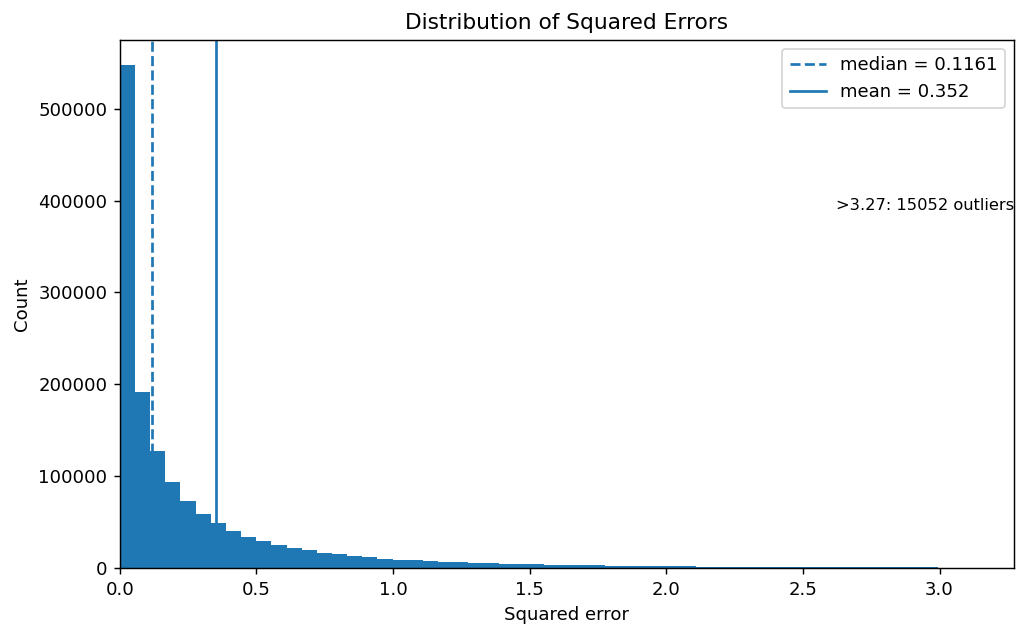

In [9]:
# pull clean squared errors
se = (pd.to_numeric(combined_df["squared_error"], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna())

# choose an x-axis cap (tweak if you like)
p95, p99, p999 = np.percentile(se, [95, 99, 99.9])
xmax = p99          # show up to the 99th percentile
tail_n = int((se > xmax).sum())

fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

# histogram only for values within the cap
data_in = se[se <= xmax]
bins = np.linspace(0, xmax, 60)
ax.hist(data_in, bins=bins)

# annotate mean/median (only if they fall within the shown range)
mean_val = se.mean()
med_val  = se.median()
if med_val <= xmax:
    ax.axvline(med_val, linestyle="--", linewidth=1.5, label=f"median = {med_val:.4g}")
else:
    ax.text(xmax, ax.get_ylim()[1]*0.90, f"median = {med_val:.4g} (off-scale)",
            ha="right", va="top", fontsize=9)

if mean_val <= xmax:
    ax.axvline(mean_val, linestyle="-", linewidth=1.5, label=f"mean = {mean_val:.4g}")
else:
    ax.text(xmax, ax.get_ylim()[1]*0.80, f"mean = {mean_val:.4g} (off-scale)",
            ha="right", va="top", fontsize=9)

# x-axis limits and a note about the hidden tail
ax.set_xlim(0, xmax)
if tail_n > 0:
    ax.text(xmax, ax.get_ylim()[1]*0.70, f">{xmax:.3g}: {tail_n} outliers",
            ha="right", va="top", fontsize=9)

ax.set_title("Distribution of Squared Errors")
ax.set_xlabel("Squared error")
ax.set_ylabel("Count")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


### Top 100 proteins by mean squared error-cosine similarity-pearson correlation

In [121]:
# Per-protein ranking tables: MAE, cosine similarity, Pearson correlation
def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan


# --- helpers
def _cos_sim_from_group(g, eps=1e-12):
    """Cosine similarity robust to NaNs/zero vectors."""
    tt = g[['true', 'predicted']].apply(pd.to_numeric, errors='coerce').dropna()
    if tt.empty:
        return np.nan
    a = tt['true'].to_numpy()
    b = tt['predicted'].to_numpy()
    denom = np.linalg.norm(a) * np.linalg.norm(b) + eps
    return float(np.dot(a, b) / denom)


per_protein = (
    combined_df.groupby('protein', sort=False)
    .apply(lambda g: pd.Series({
        'n_samples': len(g),
        'mse': g['squared_error'].mean(),
        'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
        'pearson_corr': g['true'].corr(g['predicted'])
    }))
    .reset_index()
)

top100_mae     = per_protein.sort_values('mse', ascending=True).head(100)         # lower is better
top100_cosine  = per_protein.sort_values('cosine_similarity', ascending=False).head(100)
top100_pearson = per_protein.sort_values('pearson_corr', ascending=False).head(100)

print("Top 100 proteins by lowest MAE")
display(top100_mae)

print("\nTop 100 proteins by highest cosine similarity")
display(top100_cosine)

print("\nTop 100 proteins by highest Pearson correlation")
display(top100_pearson)

Top 100 proteins by lowest MAE


,protein,n_samples,mse,cosine_similarity,pearson_corr
2662,PPP1CC,369.0,0.075699,0.372368,0.371856
946,DDX1,369.0,0.077811,0.328901,0.328624
2133,MIB1,369.0,0.085126,0.418951,0.418400
1627,HSPA8,369.0,0.085620,0.427174,0.421743
3797,UPF1,369.0,0.090651,0.475316,0.464729
...,...,...,...,...,...
1236,FAM98A,369.0,0.127474,0.450220,0.447847
426,BAG6,369.0,0.127665,0.422322,0.422099
699,CEP350,369.0,0.127725,0.428417,0.421063
2740,RPL23,369.0,0.127768,0.353518,0.353121



Top 100 proteins by highest cosine similarity


,protein,n_samples,mse,cosine_similarity,pearson_corr
821,CORO1A,369.0,0.545767,0.883462,0.879663
1666,IGF2BP1,369.0,0.594848,0.875025,0.871826
3864,VIM,369.0,0.618242,0.874629,0.874611
280,ARHGDIB,369.0,0.804340,0.870230,0.866663
1386,GNG12,369.0,0.595687,0.867991,0.868025
...,...,...,...,...,...
1897,LGALS1,369.0,0.761864,0.815935,0.815869
2693,PRDX2,369.0,0.611012,0.815901,0.815405
1294,FSTL1,369.0,0.970446,0.815531,0.815459
1472,H2AFY2,369.0,0.879947,0.815375,0.814682



Top 100 proteins by highest Pearson correlation


,protein,n_samples,mse,cosine_similarity,pearson_corr
821,CORO1A,369.0,0.545767,0.883462,0.879663
3864,VIM,369.0,0.618242,0.874629,0.874611
1666,IGF2BP1,369.0,0.594848,0.875025,0.871826
1386,GNG12,369.0,0.595687,0.867991,0.868025
280,ARHGDIB,369.0,0.804340,0.870230,0.866663
...,...,...,...,...,...
1161,ERAP2,369.0,0.816224,0.816246,0.815550
1294,FSTL1,369.0,0.970446,0.815531,0.815459
2693,PRDX2,369.0,0.611012,0.815901,0.815405
1472,H2AFY2,369.0,0.879947,0.815375,0.814682


In [122]:
# Intersection
set_mae  = set(top100_mae['protein'])
set_cos  = set(top100_cosine['protein'])
set_pear = set(top100_pearson['protein'])
inter_prots = sorted(set_mae & set_cos & set_pear)

print(f"Proteins in the intersection of all three top-100 lists: {len(inter_prots)}")

if len(inter_prots) == 0:
    print("No overlap across the three lists.")
else:
    # Add ranks for context
    pp_idx = per_protein.set_index('protein')
    ranked = pp_idx.assign(
        mae_rank=pp_idx['mae'].rank(method='min', ascending=True).astype(int),
        cosine_rank=pp_idx['cosine_similarity'].rank(method='min', ascending=False).astype(int),
        pearson_rank=pp_idx['pearson_corr'].rank(method='min', ascending=False).astype(int),
    )

    intersection_table = (
        ranked.loc[inter_prots, ['n_samples', 'mae', 'mae_rank',
                                 'cosine_similarity', 'cosine_rank',
                                 'pearson_corr', 'pearson_rank']]
        .sort_values(['mae', 'cosine_rank', 'pearson_rank'])
        .reset_index()
        .rename(columns={'protein': 'protein'})
    )

    display(intersection_table)

Proteins in the intersection of all three top-100 lists: 0
No overlap across the three lists.


### Error Distributions and thresholds 

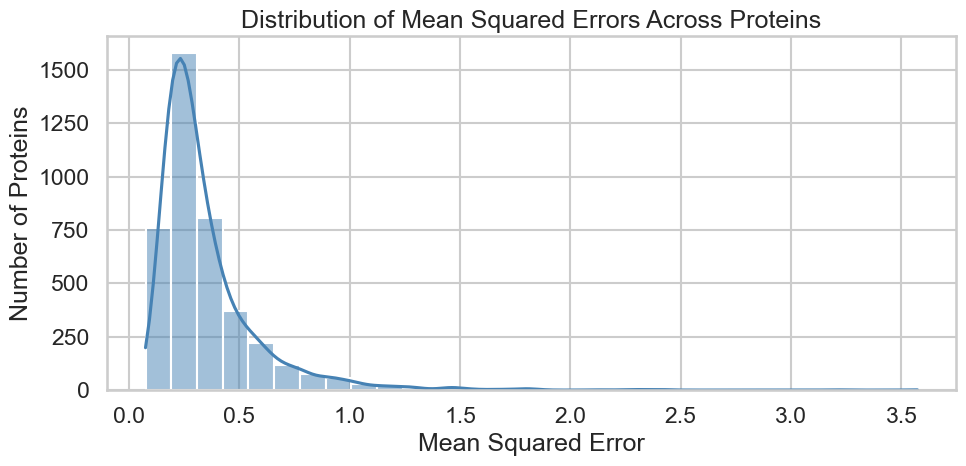

In [123]:
# Compute mean absolute error for each protein across samples
protein_means = combined_df.groupby("protein")["squared_error"].mean().reset_index()
protein_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_means["mean_squared_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Mean Squared Errors Across Proteins")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

Proteins with mean_squared_error < 0.1: 14


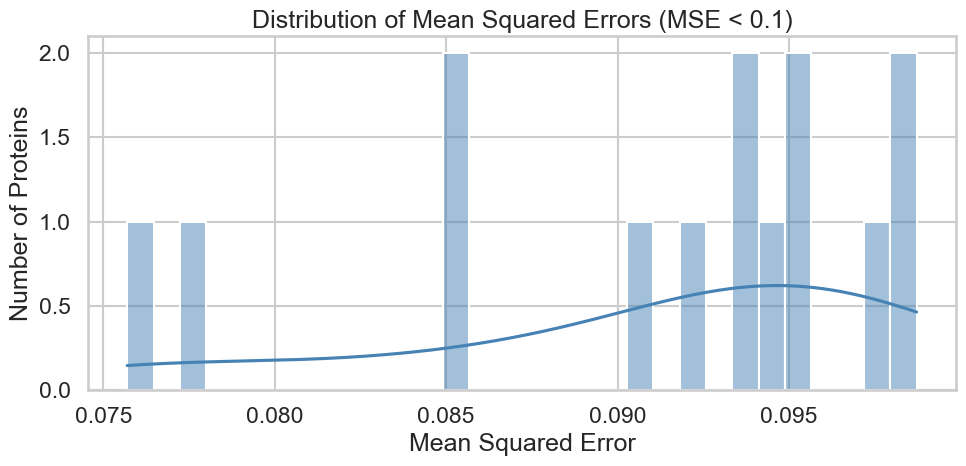


Table: Proteins with MSE < 0.100 (sorted ascending)


,protein,mean_squared_error
0,PPP1CC,0.075699
1,DDX1,0.077811
2,MIB1,0.085126
3,HSPA8,0.085620
4,UPF1,0.090651
5,WAPAL,0.092189
6,TAF6,0.093735
7,TCERG1,0.093876
8,DDX41,0.094287
9,EFTUD2,0.095080


In [124]:
# MAE < 0.1
threshold = 0.1

# mask + subset for plotting
mask = protein_means["mean_squared_error"] < threshold
subset = protein_means.loc[mask, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

    # --- table of proteins with MSE < threshold ---
    # If there's a 'protein' column, use it; otherwise, lift the index into a column.
    if "protein" in protein_means.columns:
        table = protein_means.loc[mask, ["protein", "mean_squared_error"]].copy()
    else:
        table = (
            protein_means.loc[mask, ["mean_squared_error"]]
            .reset_index()
            .rename(columns={"index": "protein"})
        )

    # sort for readability and format
    table = table.sort_values("mean_squared_error").reset_index(drop=True)
    table["mean_squared_error"] = table["mean_squared_error"].astype(float)

    # Display nicely in notebooks (falls back to print if display isn't available)
    try:
        from IPython.display import display
        print("\nTable: Proteins with MSE < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Proteins with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Proteins with mean_squared_error < 0.2: 885


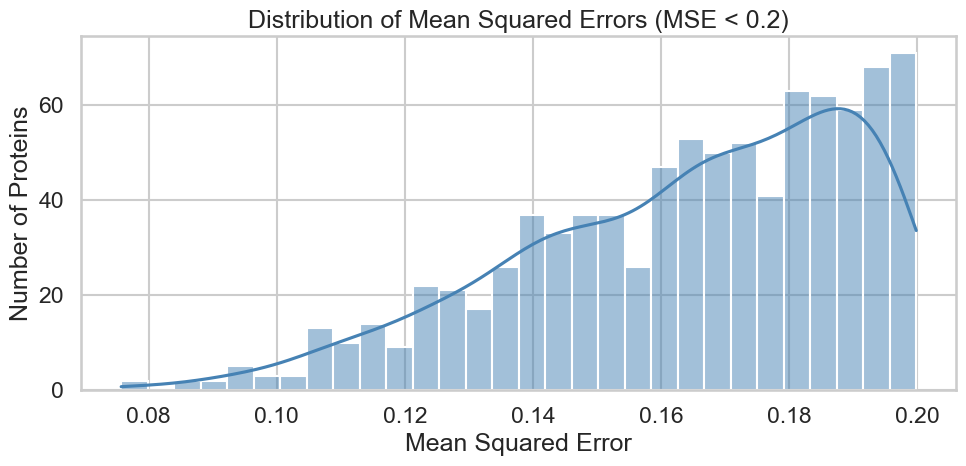

In [125]:
# Cell: MAE < 0.2
threshold = 0.2
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.2)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


Proteins with mean_squared_error < 0.3: 2257


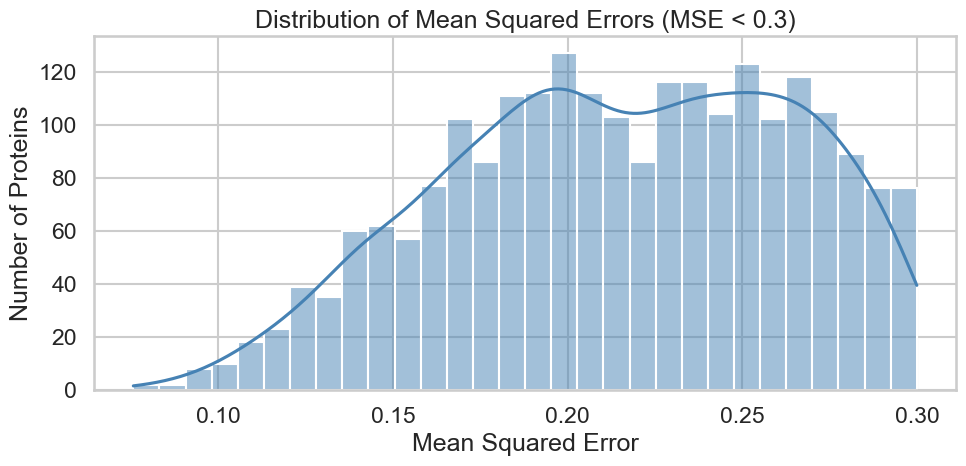

In [126]:
# Cell: MAE < 0.3
threshold = 0.3
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.3)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


Proteins with mean_squared_error < 0.3: 2257


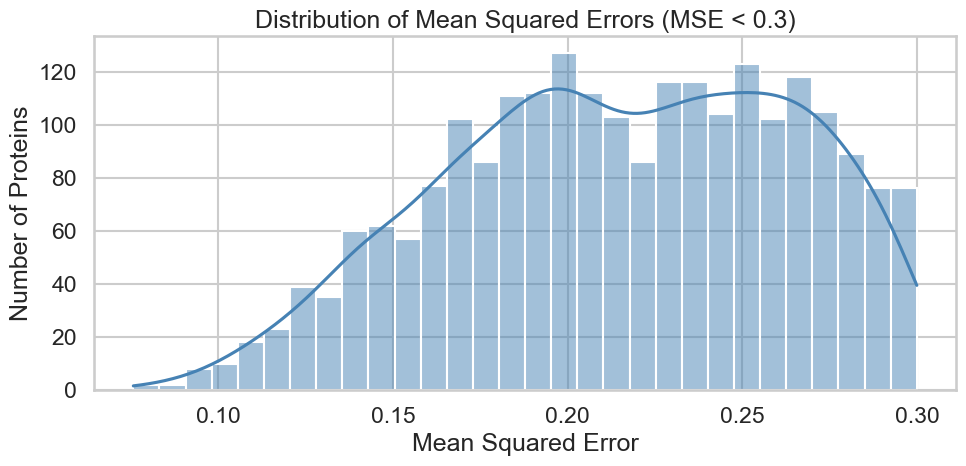

In [127]:
# Cell: MSE < 0.3
threshold = 0.3
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.3)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


### Other per-protein plots

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


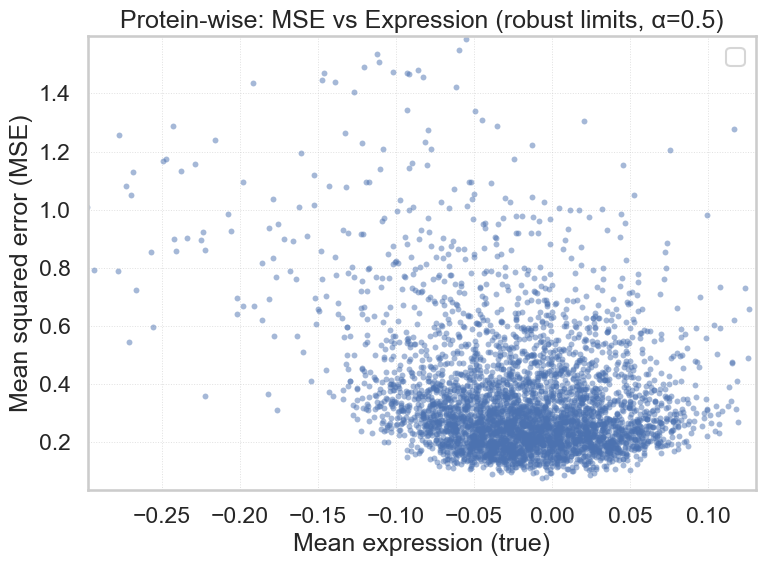

In [128]:
# MSE vs expression with robust limits and readable 1:1 line

# Recompute per-protein summary (safe if it already exists)
prot_perf = (
    combined_df.groupby('protein')
    .agg(expression=('true', 'mean'),
         mse=('squared_error', 'mean'),
         mae=('abs_error', 'mean'))
    .reset_index()
)

x = prot_perf['expression'].to_numpy()
y = prot_perf['mse'].to_numpy()

# Robust axis limits (clip to 0.5–99.5 percentiles and pad 5%)
x_lo, x_hi = np.nanpercentile(x, [0.5, 99.5])
y_lo, y_hi = np.nanpercentile(y, [0.5, 99.5])
x_pad = 0.05 * (x_hi - x_lo) if np.isfinite(x_hi - x_lo) else 1.0
y_pad = 0.05 * (y_hi - y_lo) if np.isfinite(y_hi - y_lo) else 1.0
xlim = (x_lo - x_pad, x_hi + x_pad)
ylim = (y_lo - y_pad, y_hi + y_pad)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_perf, x='expression', y='mse',
    s=18, alpha=0.5, linewidth=0, edgecolor=None
)


plt.xlim(*xlim)
plt.ylim(*ylim)
plt.xlabel('Mean expression (true)')
plt.ylabel('Mean squared error (MSE)')
plt.title('Protein-wise: MSE vs Expression (robust limits, α=0.5)')
plt.grid(True, linestyle=':', linewidth=0.7, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


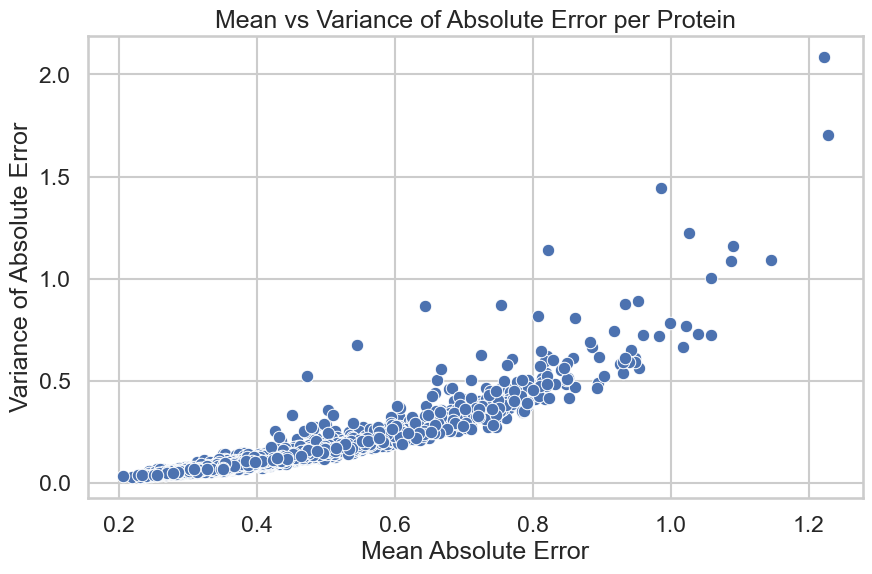

In [129]:
# Mean and variance per protein
protein_stats = combined_df.groupby('protein')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=protein_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per Protein")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


#### mean error vs variance of true values

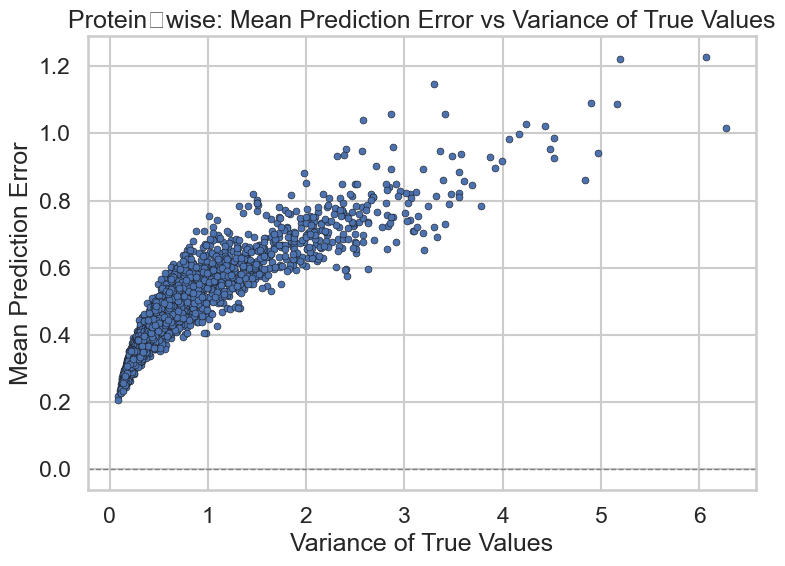

In [130]:
#Aggregate per protein 

prot_stats = (
    combined_df
    .groupby('protein')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true   = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Protein‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

### Cosine similaity 

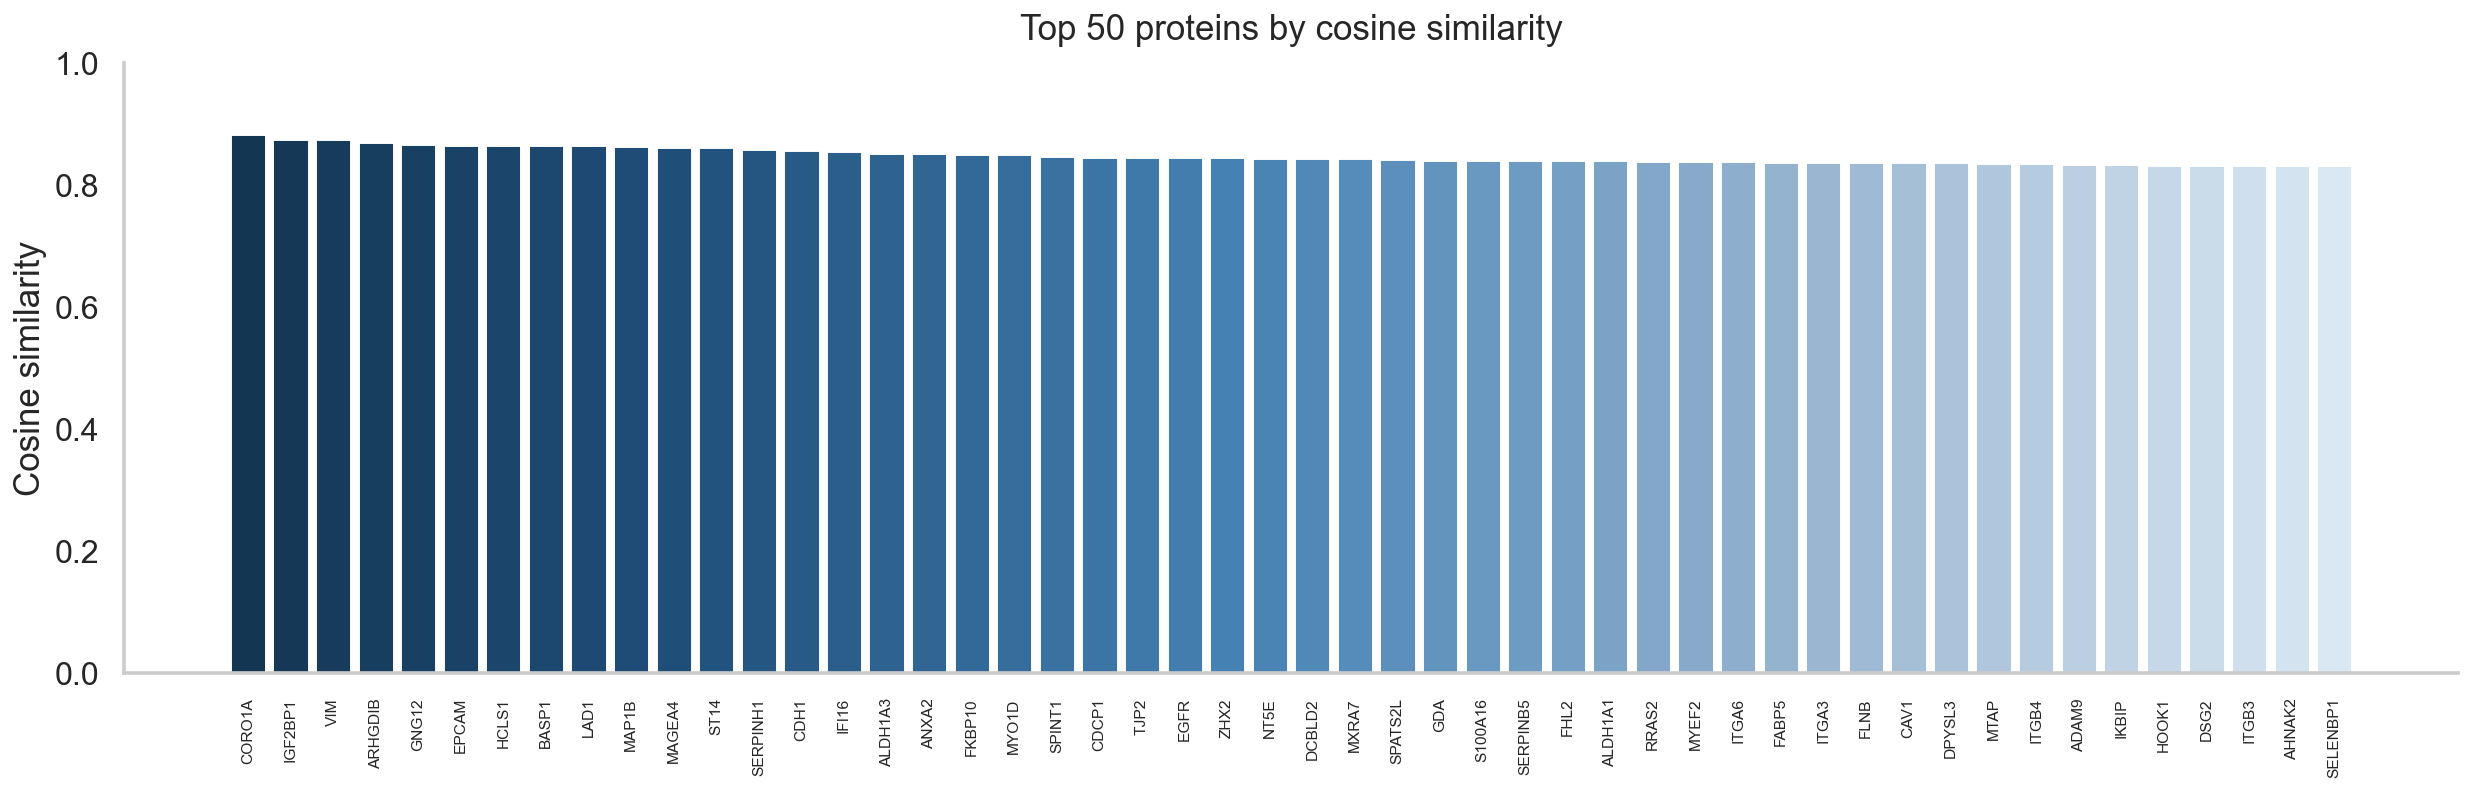

In [131]:
# Top 50, vertical bars, steelblue gradient
# prep
df = per_protein.copy()
if 'protein' in df.columns:
    df = df.set_index('protein')

df_top = (
    df[['cosine_similarity']]
    .dropna()
    .sort_values('cosine_similarity', ascending=False)
    .head(50)
)

vals   = df_top['cosine_similarity'].to_numpy()
labels = df_top.index.astype(str)

# custom steelblue gradient (deep navy → steelblue → pale)
steelblue_cmap = LinearSegmentedColormap.from_list(
    "steelblue_ramp",
    ["#0f2d45", "#1f4e79", "#4682B4", "#9ab6d1", "#e2eef7"]
)

# color by rank so the gradient flows left→right
colors = steelblue_cmap(np.linspace(0.07, 0.97, len(vals)))

fig, ax = plt.subplots(figsize=(18, 6), dpi=140)

x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85)

# labels & limits
ax.set_title('Top 50 proteins by cosine similarity', pad=12)
ax.set_ylabel('Cosine similarity')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_ylim(0, max(1.0, vals.max() + 0.05))

# subtle grid & cleanup
ax.grid(False, which='both')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


How many prteins after applying cosine similarity threshold of 0.5, 0.6, 0.7, 0.8, 0.9

In [132]:
# Summary table for cosine similarity thresholds
df = per_protein.copy()
if 'protein' in df.columns:
    df = df.set_index('protein')

# total rows considered (robust to NaNs)
total = int(df['cosine_similarity'].notna().sum())

thresholds = [0.5, 0.6, 0.7, 0.8]
rows = []
for t in thresholds:
    n = int((df['cosine_similarity'] > t).sum())
    pct = (n / total * 100) if total else 0.0
    rows.append({"threshold": f">{t:.1f}", "n_proteins": n, "% of total": f"{pct:.1f}%"})

summary = pd.DataFrame(rows).set_index("threshold")

print(f"Total proteins considered: {total}\n")
print(summary.to_string())


Total proteins considered: 4079

           n_proteins % of total
threshold                       
>0.5             2726      66.8%
>0.6             1542      37.8%
>0.7              694      17.0%
>0.8              145       3.6%


### Comparison with baseline #to do

# Samples analysis


### Top 100 samples by mean squared error, cosine similarity, pearson correlation

In [133]:
# Per-sample metrics from combined_df → samples_df (robust to NaNs/±∞)

import numpy as np
import pandas as pd

eps = 1e-12

dfc = combined_df.copy()

# Pick the sample column
sample_col = 'LOO sample' if 'LOO sample' in dfc.columns else ('sample' if 'sample' in dfc.columns else None)
if sample_col is None:
    raise KeyError("Neither 'LOO sample' nor 'sample' column found in combined_df.")

# Coerce to numeric and clean infinities
dfc['true'] = pd.to_numeric(dfc['true'], errors='coerce')
dfc['predicted'] = pd.to_numeric(dfc['predicted'], errors='coerce')
dfc = dfc.replace([np.inf, -np.inf], np.nan)

# Row-wise errors
dfc['abs_error']     = (dfc['true'] - dfc['predicted']).abs()
dfc['squared_error'] = (dfc['true'] - dfc['predicted'])**2
dfc['rel_error']     = dfc['abs_error'] / (dfc['true'].abs() + eps)

def _stats_from_group(g, eps=1e-12):
    # numeric + finite pairs for similarity/corr
    tt = pd.DataFrame({
        'true': pd.to_numeric(g['true'], errors='coerce'),
        'predicted': pd.to_numeric(g['predicted'], errors='coerce')
    }).replace([np.inf, -np.inf], np.nan).dropna()

    # errors (mean over all rows in the group, NaN-safe)
    mae = pd.to_numeric(g['abs_error'], errors='coerce').mean()
    mse = pd.to_numeric(g['squared_error'], errors='coerce').mean()
    rmse = np.sqrt(mse) if pd.notna(mse) else np.nan

    # cosine similarity (only over valid pairs)
    if tt.empty:
        cos = np.nan
        r = np.nan
    else:
        a = tt['true'].to_numpy()
        b = tt['predicted'].to_numpy()
        denom = np.linalg.norm(a) * np.linalg.norm(b) + eps
        cos = float(np.dot(a, b) / denom)
        r = tt['true'].corr(tt['predicted'])

    return pd.Series({
        'n_proteins': int(len(g)),
        'mae': mae,
        'mse': mse,
        'rmse': rmse,
        'cosine_similarity': cos,
        'pearson_corr': r
    })

samples_df = (
    dfc.groupby(sample_col, sort=False)
       .apply(_stats_from_group)
       .reset_index()
       .rename(columns={sample_col: 'sample'})
)

print(f"samples_df rows: {len(samples_df)}")
samples_df.head()


samples_df rows: 369


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
0,MDAMB468_BREAST,4079.0,0.306244,0.179989,0.424251,0.639061,0.638649
1,SH4_SKIN,4079.0,0.301136,0.166055,0.407499,0.680645,0.680710
2,AU565_BREAST,4079.0,0.313832,0.174342,0.417542,0.728204,0.730422
3,KMRC1_KIDNEY,4079.0,0.333248,0.198764,0.445830,0.660783,0.648253
4,CAL51_BREAST,4079.0,0.276662,0.141632,0.376341,0.671847,0.668790


In [134]:

top100_mse     = samples_df.sort_values('mse', ascending=True).head(100)               # lower is better
top100_mae     = samples_df.sort_values('mae', ascending=True).head(100)               # optional: also show by MAE
top100_cosine  = samples_df.sort_values('cosine_similarity', ascending=False).head(100)
top100_pearson = samples_df.sort_values('pearson_corr',       ascending=False).head(100)

print("Top 100 samples by lowest MSE")
display(top100_mse)

print("\nTop 100 samples by lowest MAE")
display(top100_mae)

print("\nTop 100 samples by highest cosine similarity")
display(top100_cosine)

print("\nTop 100 samples by highest Pearson correlation")
display(top100_pearson)


Top 100 samples by lowest MSE


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
17,PATU8988T_PANCREAS,4079.0,0.249695,0.108918,0.330027,0.719612,0.721589
22,A2058_SKIN,4079.0,0.246641,0.112296,0.335106,0.694928,0.695950
23,SW620_LARGE_INTESTINE,4079.0,0.259437,0.120210,0.346712,0.664177,0.667364
21,A375_SKIN,4079.0,0.280056,0.132493,0.363996,0.645934,0.646516
18,JIMT1_BREAST,4079.0,0.274680,0.140186,0.374414,0.675622,0.675567
...,...,...,...,...,...,...,...
190,SNU685_ENDOMETRIUM,4079.0,0.383332,0.257017,0.506969,0.609820,0.626554
278,HS944T_SKIN,4079.0,0.370418,0.258070,0.508006,0.486173,0.486042
175,U87MG_CENTRAL_NERVOUS_SYSTEM,4079.0,0.367756,0.258285,0.508218,0.794579,0.794685
257,ISHIKAWAHERAKLIO02ER_ENDOMETRIUM,4079.0,0.383665,0.259441,0.509353,0.725693,0.725561



Top 100 samples by lowest MAE


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
22,A2058_SKIN,4079.0,0.246641,0.112296,0.335106,0.694928,0.695950
17,PATU8988T_PANCREAS,4079.0,0.249695,0.108918,0.330027,0.719612,0.721589
23,SW620_LARGE_INTESTINE,4079.0,0.259437,0.120210,0.346712,0.664177,0.667364
18,JIMT1_BREAST,4079.0,0.274680,0.140186,0.374414,0.675622,0.675567
4,CAL51_BREAST,4079.0,0.276662,0.141632,0.376341,0.671847,0.668790
...,...,...,...,...,...,...,...
34,SKMEL3_SKIN,4079.0,0.380804,0.243727,0.493687,0.713069,0.714376
57,NCIH1693_LUNG,4079.0,0.382492,0.251837,0.501834,0.532005,0.531912
190,SNU685_ENDOMETRIUM,4079.0,0.383332,0.257017,0.506969,0.609820,0.626554
257,ISHIKAWAHERAKLIO02ER_ENDOMETRIUM,4079.0,0.383665,0.259441,0.509353,0.725693,0.725561



Top 100 samples by highest cosine similarity


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
269,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.401099,0.265340,0.515111,0.864188,0.863125
197,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.494587,0.459823,0.678103,0.838862,0.834492
187,HEL9217_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.464788,0.367693,0.606377,0.834361,0.835333
218,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.471100,0.384135,0.619786,0.833176,0.836510
203,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.417710,0.311644,0.558251,0.830233,0.827651
...,...,...,...,...,...,...,...
17,PATU8988T_PANCREAS,4079.0,0.249695,0.108918,0.330027,0.719612,0.721589
247,SNU449_LIVER,4079.0,0.345707,0.220386,0.469453,0.719388,0.723154
258,SNGM_ENDOMETRIUM,4079.0,0.388017,0.281433,0.530502,0.718433,0.718593
274,PC14_LUNG,4079.0,0.322168,0.187467,0.432975,0.718384,0.721279



Top 100 samples by highest Pearson correlation


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
269,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.401099,0.265340,0.515111,0.864188,0.863125
218,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.471100,0.384135,0.619786,0.833176,0.836510
187,HEL9217_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.464788,0.367693,0.606377,0.834361,0.835333
197,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.494587,0.459823,0.678103,0.838862,0.834492
203,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.417710,0.311644,0.558251,0.830233,0.827651
...,...,...,...,...,...,...,...
171,JHUEM2_ENDOMETRIUM,4079.0,0.383821,0.281466,0.530533,0.717334,0.722585
132,SNUC1_LARGE_INTESTINE,4079.0,0.474752,0.375367,0.612672,0.721830,0.722193
366,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.468337,0.361410,0.601173,0.720136,0.721895
17,PATU8988T_PANCREAS,4079.0,0.249695,0.108918,0.330027,0.719612,0.721589


In [135]:
sample_error_summary = combined_df.groupby('LOO sample').agg(
    mean_abs_error=('abs_error', 'mean'),
    std_abs_error=('abs_error', 'std'),
    mean_squared_error=('squared_error', 'mean'),
    std_squared_error=('squared_error', 'std'),
    count=('LOO sample', 'count')
).sort_values(by='mean_abs_error', ascending=False)

sample_error_summary.head()

,mean_abs_error,std_abs_error,mean_squared_error,std_squared_error,count
LOO sample,,,,,
RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.894543,0.606449,1.167898,1.472474,4079
MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.772734,0.597735,0.954317,1.459467,4079
IM95_STOMACH,0.707611,0.552146,0.805503,2.311568,4079
KNS42_CENTRAL_NERVOUS_SYSTEM,0.692550,0.514875,0.744656,1.120220,4079
MONOMAC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.689971,0.491175,0.717254,0.934138,4079


### MSE thresholding and distributions

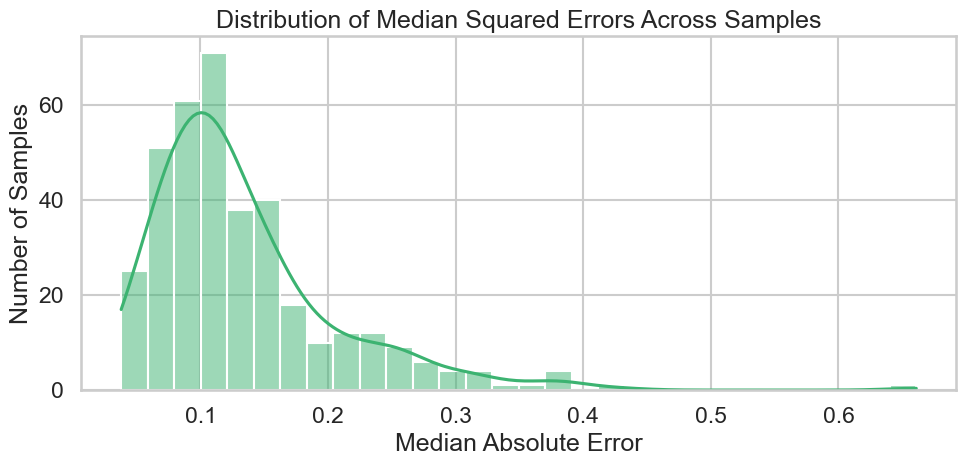

In [136]:
# Compute median absolute error across proteins for each sample
sample_medians = combined_df.groupby("LOO sample")["squared_error"].median().reset_index()
sample_medians.rename(columns={"squared_error": "median_squared_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians["median_squared_error"], bins=30, kde=True, color="mediumseagreen")

plt.title("Distribution of Median Squared Errors Across Samples")
plt.xlabel("Median Absolute Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


In [137]:
# Mean Squared Error per sample + threshold plot (< 0.1)

# column holding sample IDs (handles the space in "LOO sample")
sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"

# mean squared error across proteins for each sample
sample_means = (
    combined_df.groupby(sample_col)["squared_error"]
               .mean()
               .reset_index()
               .rename(columns={sample_col: "sample", "squared_error": "mean_squared_error"})
)

threshold = 0.1

# mask + subset for plotting
mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    # --- table of samples with MSE < threshold ---
    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )

    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with mean_squared_error < 0.1: 0
No samples below this threshold to plot.


Samples with mean_squared_error < 0.2: 43


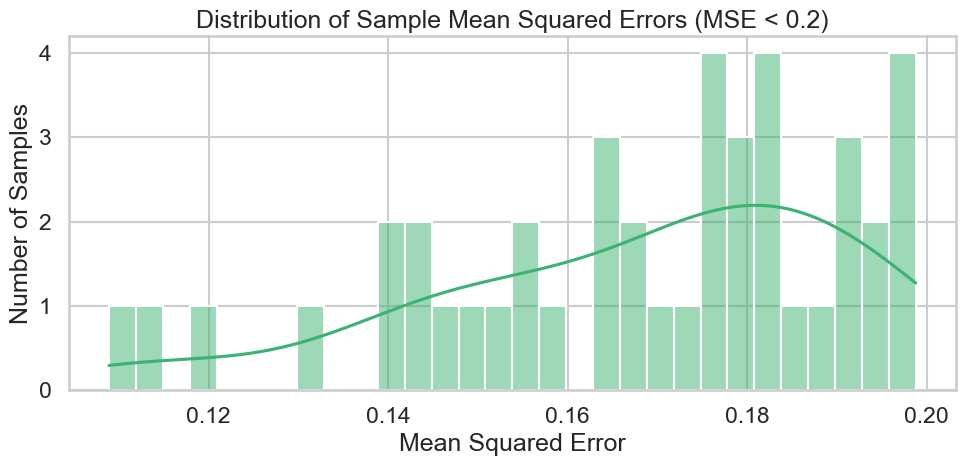


Table: Samples with MSE < 0.200 (sorted ascending)


In [138]:
threshold = 0.2

mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with mean_squared_error < 0.3: 152


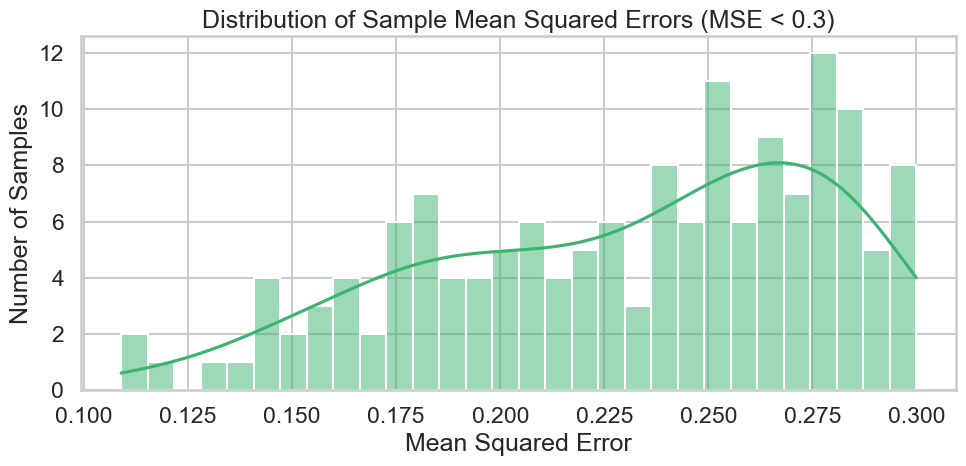


Table: Samples with MSE < 0.300 (sorted ascending)


In [139]:
threshold = 0.3

mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


### Other statistical plots on Samples

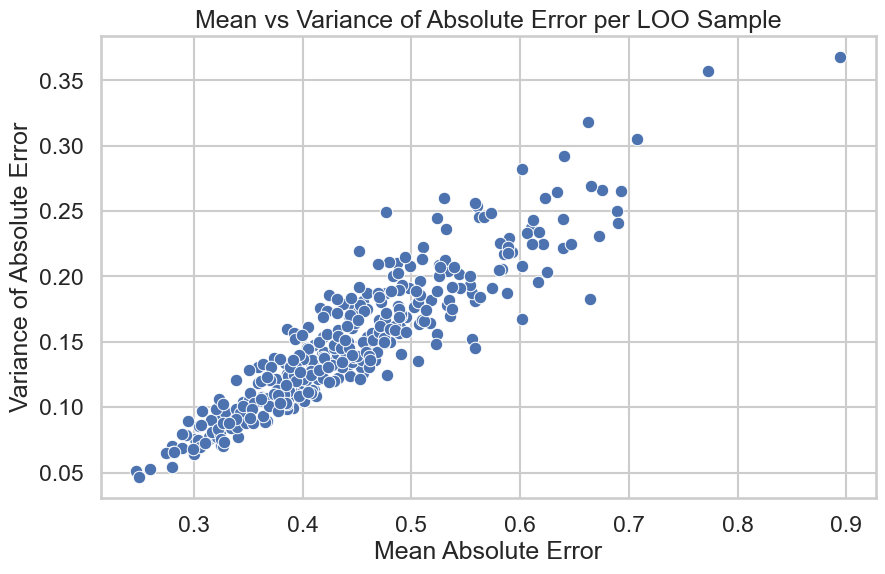

In [140]:
sample_stats = combined_df.groupby('LOO sample')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per LOO Sample")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


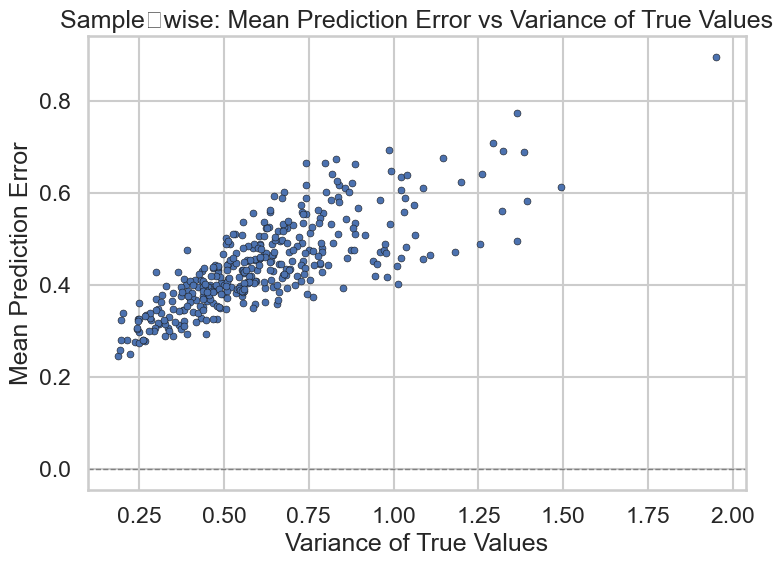

In [141]:
# Aggregate per LOO sample
sample_stats = (
    combined_df
    .groupby('LOO sample')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true    = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Sample‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

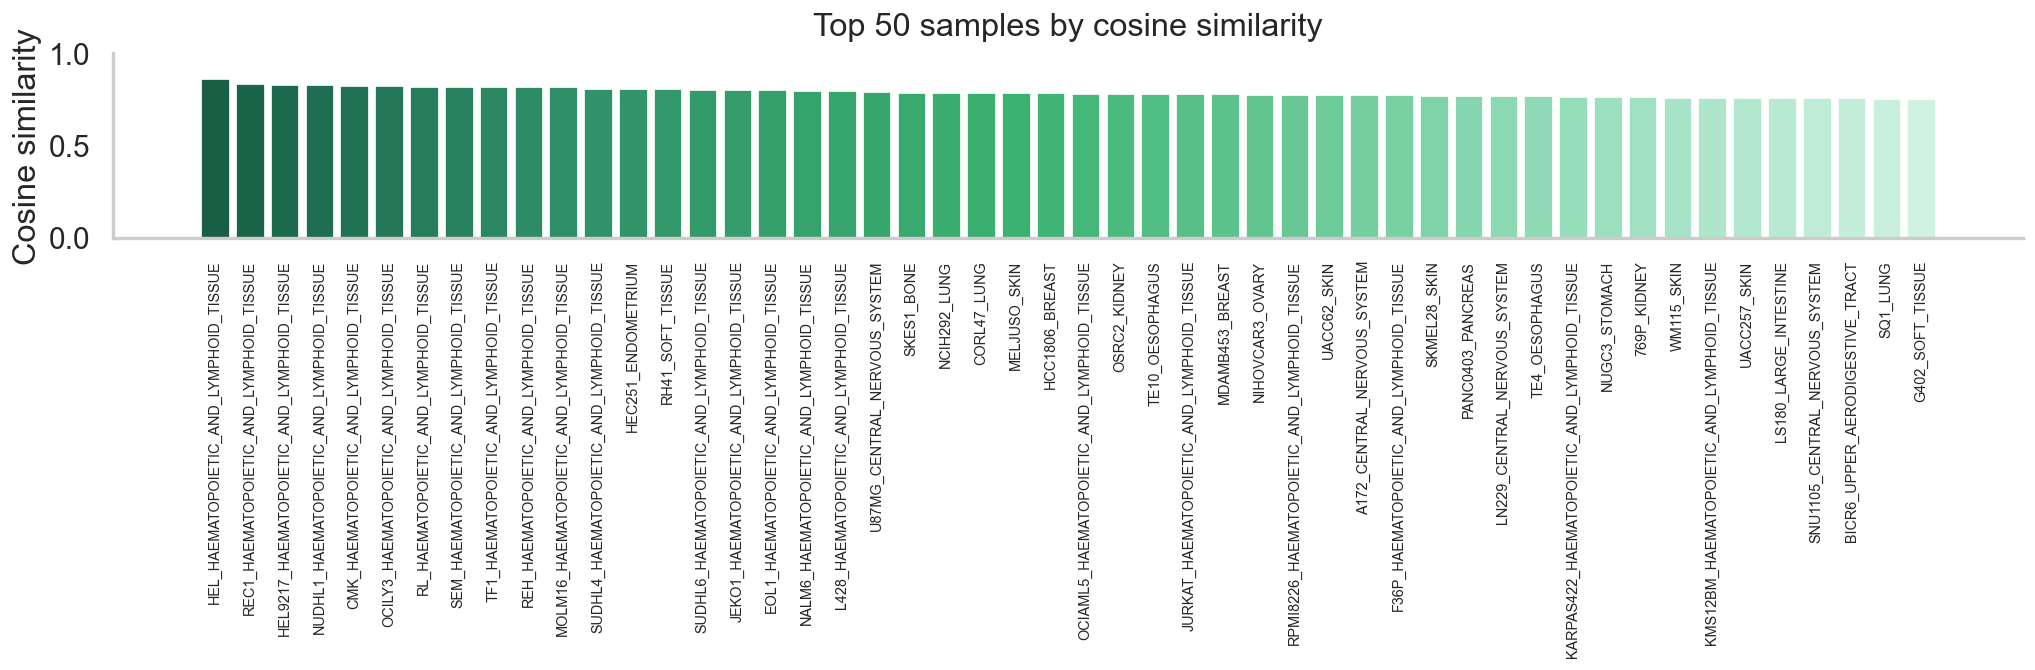

In [142]:
# Top 50 samples by cosine similarity — vertical bars, Medium SeaGreen gradient (robust)
# --- prep combined_df
dfc = combined_df.copy()

# pick sample column
sample_col = "LOO sample" if "LOO sample" in dfc.columns else ("sample" if "sample" in dfc.columns else None)
if sample_col is None:
    raise KeyError("Neither 'LOO sample' nor 'sample' column was found in combined_df.")

# ensure numeric & squared_error exists
dfc['true'] = pd.to_numeric(dfc.get('true'), errors='coerce')
dfc['predicted'] = pd.to_numeric(dfc.get('predicted'), errors='coerce')
if "squared_error" not in dfc.columns:
    dfc["squared_error"] = (dfc["true"] - dfc["predicted"])**2

# --- build samples_df
samples_df = (
    dfc.groupby(sample_col, sort=False)
       .apply(lambda g: pd.Series({
           "n_proteins": int(g.shape[0]),
           "mse": pd.to_numeric(g["squared_error"], errors='coerce').mean(),
           "cosine_similarity": _cos_sim_from_group(g),
           "pearson_corr": g["true"].corr(g["predicted"])
       }))
       .reset_index()
       .rename(columns={sample_col: "sample"})
)

# --- sort & take top-K
k = 50
df_top = (
    samples_df[["sample", "cosine_similarity"]]
    .dropna(subset=["cosine_similarity"])
    .sort_values("cosine_similarity", ascending=False)
    .head(k)
)

# handle empty case gracefully
if df_top.empty:
    print("No samples with valid cosine similarity to plot (all NaN or zero-norm).")
else:
    vals   = df_top["cosine_similarity"].to_numpy()
    labels = df_top["sample"].astype(str).to_numpy()

    # Medium SeaGreen tonality (deep green → MediumSeaGreen → pale mint)
    seagreen_cmap = LinearSegmentedColormap.from_list(
        "seagreen_ramp",
        ["#0f4d3a", "#2f8f68", "#3CB371", "#8ad9b2", "#d7f5e8"]
    )
    colors = seagreen_cmap(np.linspace(0.07, 0.97, len(vals)))

    fig, ax = plt.subplots(figsize=(16, 5.5), dpi=130)  # a bit smaller & crisper
    x = np.arange(len(vals))
    ax.bar(x, vals, color=colors, width=0.85)

    # Labels & limits
    ax.set_title("Top 50 samples by cosine similarity", pad=10)
    ax.set_ylabel("Cosine similarity")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_ylim(0, max(1.0, float(vals.max()) + 0.05))

    # Tidy up
    ax.grid(False, which='both')
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()


#### Tissues

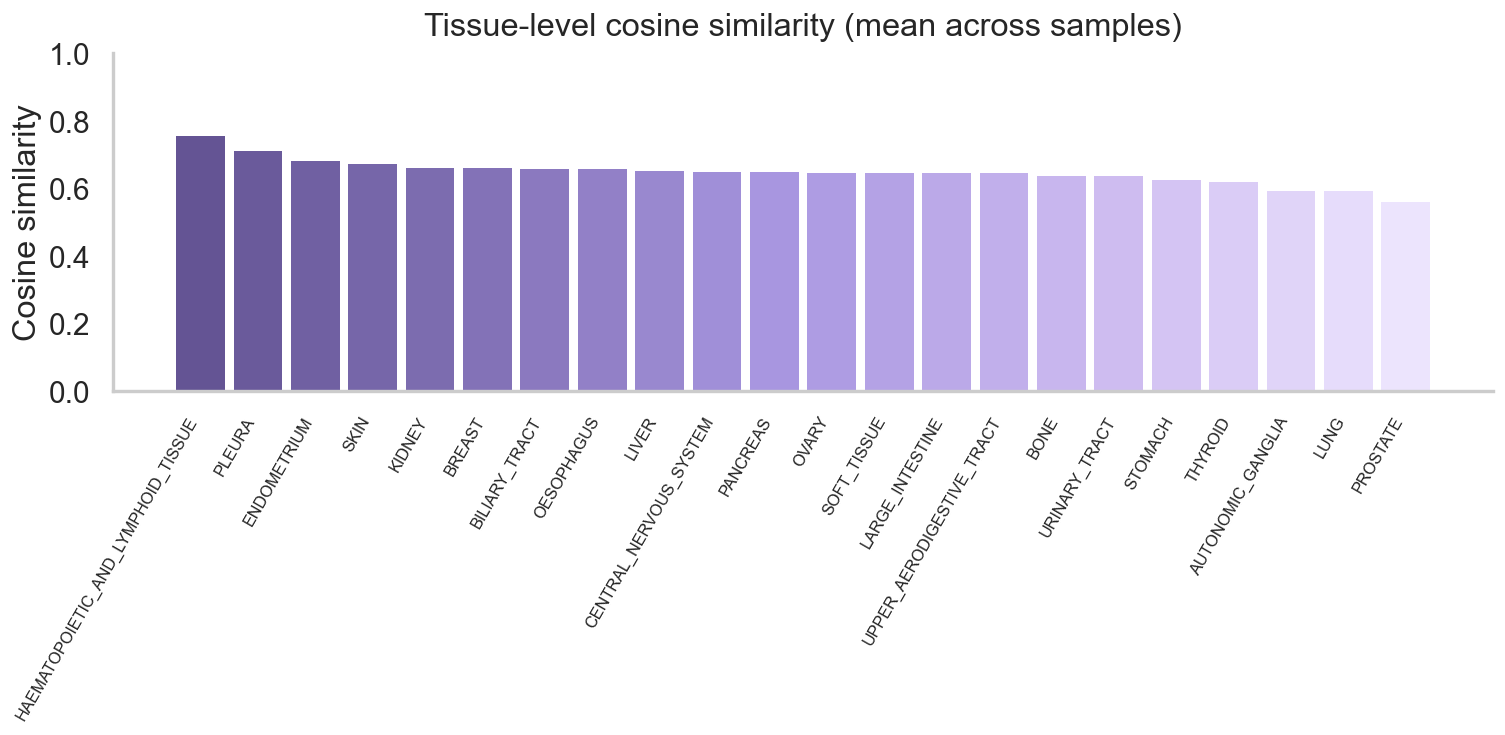

In [151]:
# --- parse tissue = everything after the first underscore
s = samples_df['sample'].astype(str).str.strip()
parts = s.str.split('_', n=1, expand=True)    # <-- use n=1 as a keyword
samples_df['tissue'] = parts[1].where(parts[1].notna() & (parts[1] != ''), parts[0])

# --- aggregate per tissue (median; switch to 'mean' if preferred)
tissue_stats = (
    samples_df.dropna(subset=['tissue', 'cosine_similarity'])
              .groupby('tissue')
              .agg(cosine_similarity=('cosine_similarity', 'mean'),
                   n_samples=('sample', 'nunique'))
              .sort_values('cosine_similarity', ascending=False)
)

vals   = tissue_stats['cosine_similarity'].to_numpy()
labels = tissue_stats.index.astype(str).to_numpy()

# Light purple (lilac) gradient
lilac_cmap = LinearSegmentedColormap.from_list(
    "lilac_ramp",
    ["#5b4b8a", "#7e6db1", "#a896e0", "#cdbbf0", "#f0e9ff"] 
)
colors = lilac_cmap(np.linspace(0.07, 0.97, len(vals)))

# dynamic width for all tissues
fig_w = max(12, 0.35 * len(vals))
fig, ax = plt.subplots(figsize=(fig_w, 6), dpi=130)

x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85, edgecolor='none', linewidth=0)

ax.set_title("Tissue-level cosine similarity (mean across samples)", pad=10)
ax.set_ylabel("Cosine similarity")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=60, ha='right', fontsize=9)
ax.set_ylim(0, max(1.0, float(vals.max()) + 0.05))

ax.set_axisbelow(True)
ax.grid(False, which='both')

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [150]:
# --- aggregate per tissue (MEAN)
tissue_table = (
    samples_df.dropna(subset=['tissue'])
              .groupby('tissue', as_index=False)
              .agg(n_samples=('sample', 'nunique'),
                   cosine_similarity=('cosine_similarity', 'mean'),
                   mse=('mse', 'mean'))
              .sort_values('cosine_similarity', ascending=False)
)

# --- display
try:
    display(
        tissue_table.style
            .format({'cosine_similarity': '{:.4f}', 'mse': '{:.6f}', 'n_samples': '{:d}'})
            .set_properties(subset=['tissue'], **{'font-weight': 'bold'})
    )
except Exception:
    print(tissue_table.to_string(index=False))

,tissue,n_samples,cosine_similarity,mse
6,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,40,0.7557,0.448636
14,PLEURA,2,0.7111,0.274776
5,ENDOMETRIUM,14,0.6819,0.350890
16,SKIN,33,0.6721,0.258595
7,KIDNEY,11,0.6610,0.335129
3,BREAST,30,0.6603,0.316903
1,BILIARY_TRACT,1,0.6579,0.251167
11,OESOPHAGUS,14,0.6572,0.324140
9,LIVER,14,0.6527,0.276226
4,CENTRAL_NERVOUS_SYSTEM,13,0.6492,0.403784


## Boxplot Protein and Samples

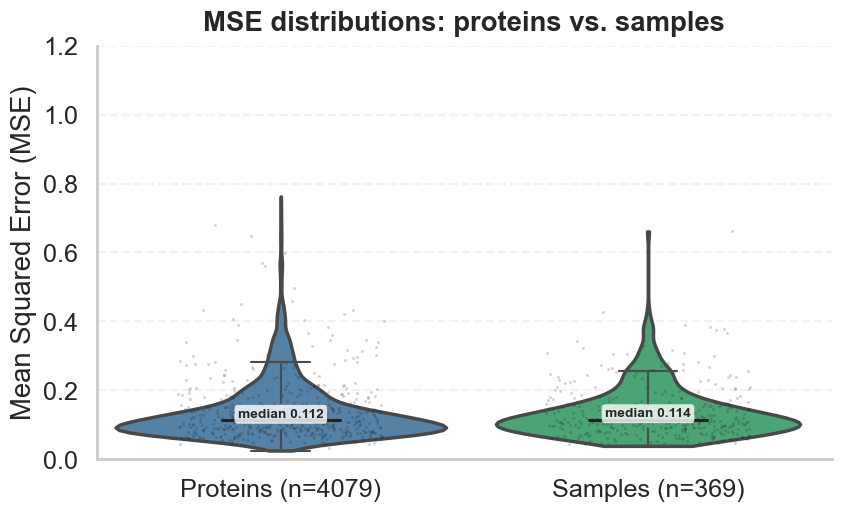

In [153]:
# Visually enhanced box/violin plot of MSE: proteins vs samples

df = combined_df.copy()
sample_col = "LOO sample" if "LOO sample" in df.columns else "sample"

# ensure squared_error exists
if "squared_error" not in df.columns:
    df["squared_error"] = (df["true"] - df["predicted"])**2

# per-group MSE
protein_mse = (
    df.groupby("protein", sort=False)["squared_error"]
      .median()
      .reset_index()
      .rename(columns={"squared_error": "mse"})
)
sample_mse = (
    df.groupby(sample_col, sort=False)["squared_error"]
      .median()
      .reset_index()
      .rename(columns={"squared_error": "mse", sample_col: "sample"})
)

# tidy for plotting
plot_df = pd.concat(
    [protein_mse.assign(group="Proteins")[["group", "mse"]],
     sample_mse.assign(group="Samples")[["group", "mse"]]],
    ignore_index=True
)

# aesthetics
palette = {"Proteins": "#4682B4",  # steelblue
           "Samples":  "#3CB371"}  # mediumseagreen
sns.set_theme(style="whitegrid", context="talk")

# y-limit trimmed to reduce extreme outlier pull
ymax = np.percentile(plot_df["mse"], 99.5)
ymax = float(np.clip(ymax * 1.05, 0.1, None))  # small buffer

fig, ax = plt.subplots(figsize=(8, 5), dpi=110)  # was (18, 6), 140


# violin (soft fill, no inner lines)
sns.violinplot(
    data=plot_df, x="group", y="mse",
    palette=palette, inner=None, cut=0, width=0.9, alpha=0.6, ax=ax
)

# box overlay (thin, clean)
sns.boxplot(
    data=plot_df, x="group", y="mse",
    width=0.32, showcaps=True, showfliers=False, boxprops={"facecolor": "white", "alpha": 0.9},
    medianprops={"linewidth": 2, "color": "#222"},
    whiskerprops={"linewidth": 1.4},
    capprops={"linewidth": 1.4},
    ax=ax
)

# light jittered points (subsample to keep it crisp)
pts = (
    plot_df.groupby("group", group_keys=False)
           .apply(lambda g: g.sample(n=min(500, len(g)), random_state=0))
)
sns.stripplot(
    data=pts, x="group", y="mse",
    color="k", alpha=0.18, size=2, jitter=0.28, ax=ax, zorder=1
)

# titles, labels, and counts
counts = {"Proteins": len(protein_mse), "Samples": len(sample_mse)}
ax.set_title("MSE distributions: proteins vs. samples", pad=10, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Mean Squared Error (MSE)")
ax.set_xticklabels([
    f"Proteins (n={counts['Proteins']})",
    f"Samples (n={counts['Samples']})"
])

# median annotations
meds = plot_df.groupby("group")["mse"].median().to_dict()
for i, g in enumerate(["Proteins", "Samples"]):
    m = meds[g]
    ax.text(i, m, f"median {m:.3f}", ha="center", va="bottom",
            fontsize=9, weight="bold",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.8))

# tidy up
ax.set_ylim(0, 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [152]:


# total rows considered (robust to NaNs)
total = int(samples_df['cosine_similarity'].notna().sum())

thresholds = [0.5, 0.6, 0.7, 0.8]
rows = []
for t in thresholds:
    n = int((samples_df['cosine_similarity'] > t).sum())
    pct = (n / total * 100) if total else 0.0
    rows.append({"threshold": f">{t:.1f}", "n_proteins": n, "% of total": f"{pct:.1f}%"})

summary = pd.DataFrame(rows).set_index("threshold")

print(f"Total Samples considered: {total}\n")
print(summary.to_string())

Total Samples considered: 369

           n_proteins % of total
threshold                       
>0.5              340      92.1%
>0.6              266      72.1%
>0.7              113      30.6%
>0.8               18       4.9%


# MAE vs Prot- Encoding Gene correlations

In [145]:
corrs

,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


# Cluster-Wise analysis

In [146]:
clusters = pd.read_csv("xgb_res/protein_clusters_k3.csv")

In [147]:
clusters

,Protein,Cluster
0,A2M,3
1,AAAS,3
2,AACS,3
3,AAGAB,1
4,AAK1,2
...,...,...
5108,ZRANB2,1
5109,ZW10,3
5110,ZWILCH,1
5111,ZYX,3


Distributions

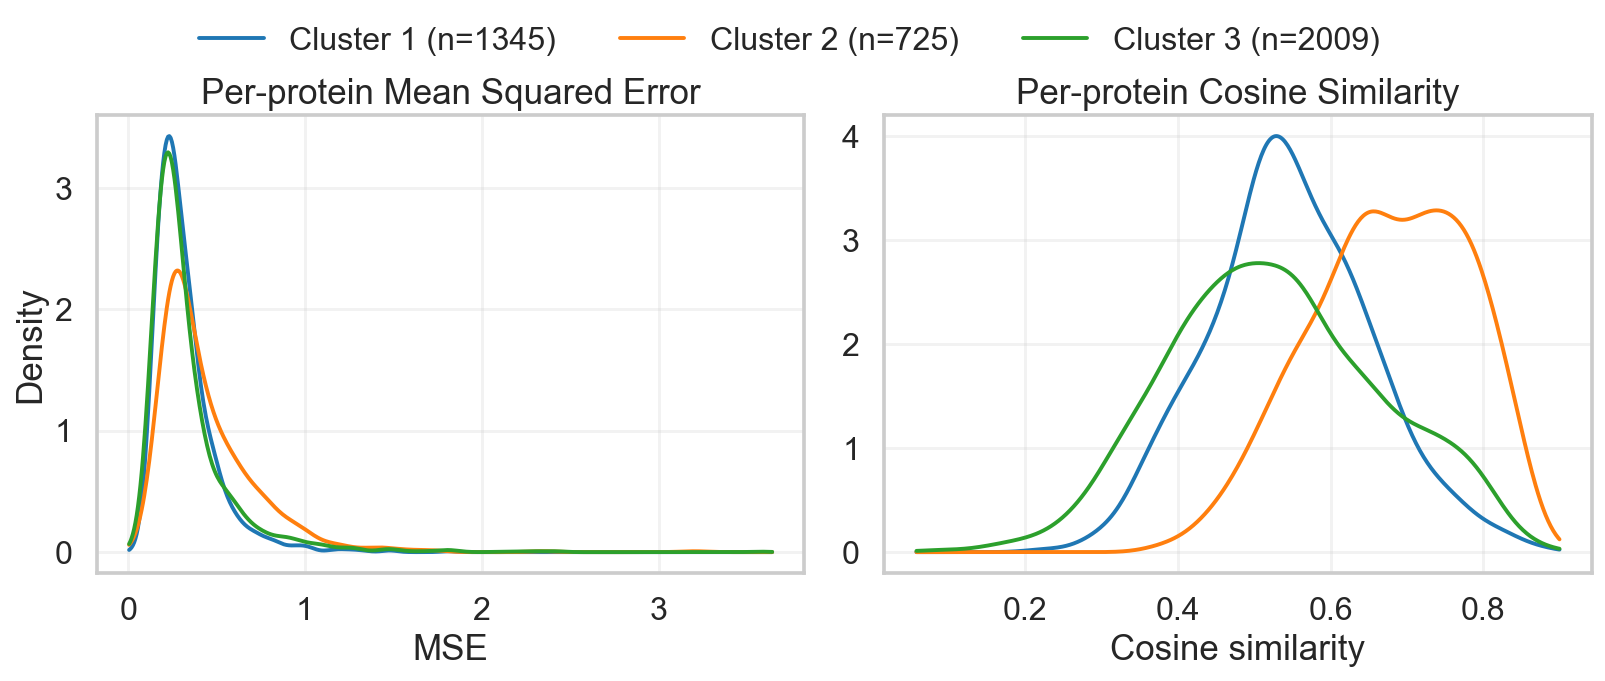

In [148]:
# Side-by-side KDEs by cluster: per-protein MSE (left) and cosine similarity (right)
# Robust to NaNs/±∞ and zero-variance groups

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# --- config
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}  # blue, orange, green

# --- helpers
def _cos_sim(a, b, eps=1e-12):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]
    n = min(len(a), len(b))
    if n == 0: 
        return np.nan
    a = a[:n]; b = b[:n]
    denom = np.linalg.norm(a) * np.linalg.norm(b) + eps
    return float(np.dot(a, b) / denom)

def _pad_range(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return (0.0, 1.0)
    xmin, xmax = float(np.min(x)), float(np.max(x))
    if xmin == xmax:
        # tiny span around the single value
        span = max(abs(xmin), 1.0) * 1e-3
        return xmin - span, xmax + span
    span = xmax - xmin
    pad = 0.02 * span
    return xmin - pad, xmax + pad

def _finite_clean(arr):
    arr = np.asarray(arr, dtype=float)
    return arr[np.isfinite(arr)]

# --- inputs
dfc = combined_df.copy()

# coerce to numeric & ensure squared_error exists
dfc['true'] = pd.to_numeric(dfc['true'], errors='coerce')
dfc['predicted'] = pd.to_numeric(dfc['predicted'], errors='coerce')
if "squared_error" not in dfc.columns:
    dfc["squared_error"] = (dfc["true"] - dfc["predicted"])**2

# --- per-protein metrics
prot_mse = (
    dfc.groupby("protein", sort=False)["squared_error"]
       .mean()
       .reset_index()
       .rename(columns={"protein": "Protein", "squared_error": "mse"})
)
prot_mse["mse"] = pd.to_numeric(prot_mse["mse"], errors="coerce")

prot_cos = (
    dfc.groupby("protein", sort=False)
       .apply(lambda g: _cos_sim(g["true"].to_numpy(), g["predicted"].to_numpy()))
       .reset_index(name="cosine_similarity")
       .rename(columns={"protein": "Protein"})
)
prot_cos["cosine_similarity"] = pd.to_numeric(prot_cos["cosine_similarity"], errors="coerce")

# merge with cluster mapping (expects columns: Protein, Cluster)
df_mse = prot_mse.merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")
df_cos = prot_cos.merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")

# clean non-finite rows
df_mse = df_mse[np.isfinite(df_mse["mse"])]
df_cos = df_cos[np.isfinite(df_cos["cosine_similarity"])]

# --- x-ranges (based on finite values only)
xmin_mse, xmax_mse = _pad_range(df_mse["mse"].values)
xmin_cos, xmax_cos = _pad_range(df_cos["cosine_similarity"].values)
xr_mse = np.linspace(xmin_mse, xmax_mse, 512)
xr_cos = np.linspace(xmin_cos, xmax_cos, 512)

# --- plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=140)

# Left: MSE KDEs
handles_labels = []
for c in sorted(pd.unique(df_mse["Cluster"].dropna())):
    vals = _finite_clean(df_mse.loc[df_mse["Cluster"] == c, "mse"].to_numpy())
    if vals.size >= 2 and np.std(vals) > 0:
        kde = gaussian_kde(vals)  # add bw_method=0.3 if you want smoother curves
        h = ax1.plot(xr_mse, kde(xr_mse), lw=2, color=palette.get(int(c), "#333"))[0]
        handles_labels.append((h, f"Cluster {int(c)} (n={len(vals)})"))
    elif vals.size > 0:
        # fallback: draw a thin vertical line at median
        m = float(np.median(vals))
        h = ax1.axvline(m, ymax=0.12, lw=2, color=palette.get(int(c), "#333"))
        handles_labels.append((h, f"Cluster {int(c)} (n={len(vals)})"))

ax1.set_title("Per-protein Mean Squared Error")
ax1.set_xlabel("MSE")
ax1.set_ylabel("Density")
ax1.grid(alpha=0.25)

# Right: Cosine similarity KDEs
for c in sorted(pd.unique(df_cos["Cluster"].dropna())):
    vals = _finite_clean(df_cos.loc[df_cos["Cluster"] == c, "cosine_similarity"].to_numpy())
    if vals.size >= 2 and np.std(vals) > 0:
        kde = gaussian_kde(vals)
        ax2.plot(xr_cos, kde(xr_cos), lw=2, color=palette.get(int(c), "#333"))
    elif vals.size > 0:
        m = float(np.median(vals))
        ax2.axvline(m, ymax=0.12, lw=2, color=palette.get(int(c), "#333"))

ax2.set_title("Per-protein Cosine Similarity")
ax2.set_xlabel("Cosine similarity")
ax2.grid(alpha=0.25)

# Shared legend (use handles from the left plot)
if handles_labels:
    handles, labels = zip(*handles_labels)
    fig.legend(handles, labels, ncol=3, loc="upper center", frameon=False, bbox_to_anchor=(0.5, 1.01))

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Scatterplot

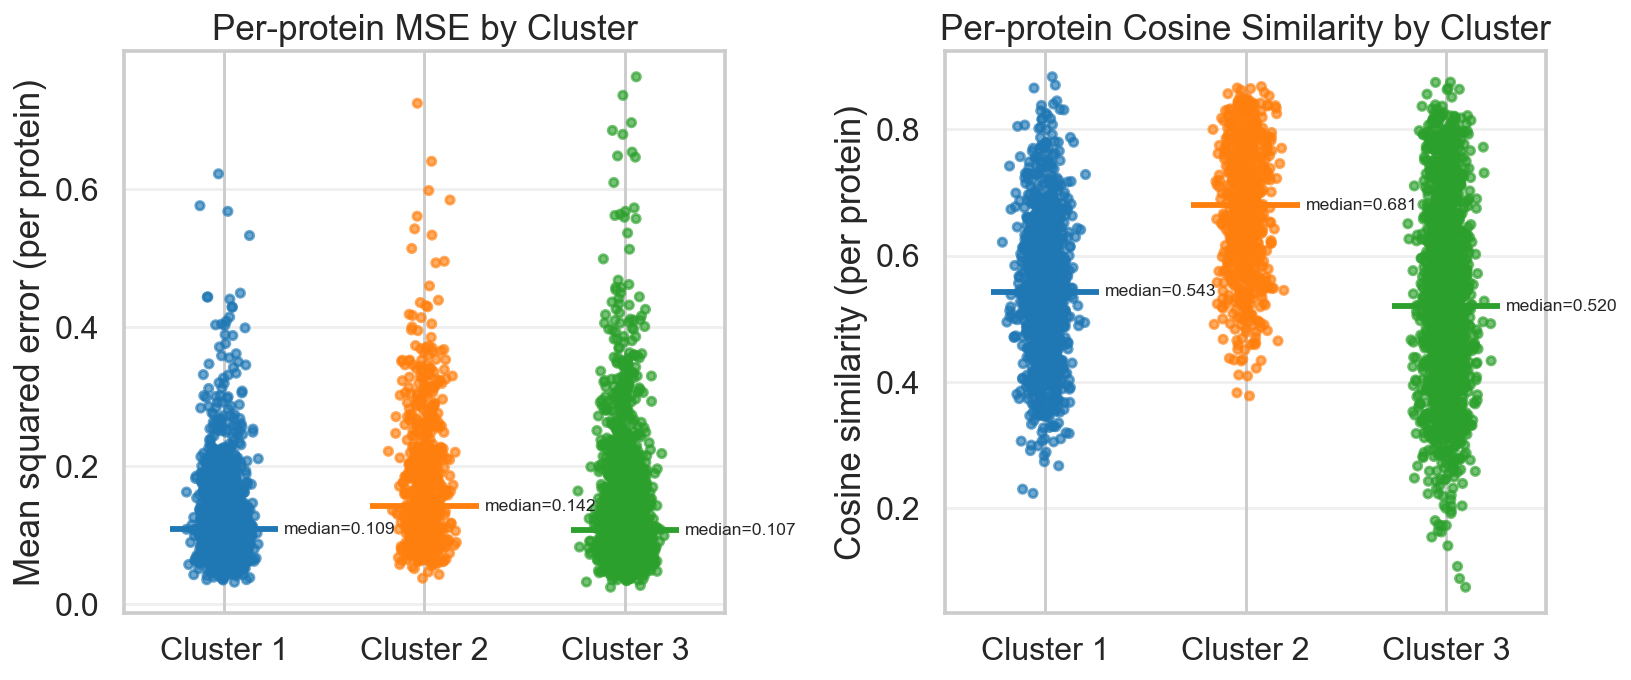

In [154]:
# Side-by-side jittered scatters by cluster: per-protein MSE (left) and cosine similarity (right)
# NaN/Inf/zero-norm safe
# --- config
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}  # steelblue, orange, green

# --- helpers
def _cos_from_group(g, eps=1e-12):
    """Cosine similarity robust to NaNs/Inf and zero-norm."""
    t = pd.to_numeric(g['true'], errors='coerce')
    p = pd.to_numeric(g['predicted'], errors='coerce')
    tp = pd.DataFrame({'t': t, 'p': p}).replace([np.inf, -np.inf], np.nan).dropna()
    if tp.empty:
        return np.nan
    a = tp['t'].to_numpy()
    b = tp['p'].to_numpy()
    denom = np.linalg.norm(a) * np.linalg.norm(b) + eps
    return float(np.dot(a, b) / denom)

def _finite_mask(*cols):
    m = np.ones_like(np.asarray(cols[0], dtype=float), dtype=bool)
    for c in cols:
        arr = np.asarray(c, dtype=float)
        m &= np.isfinite(arr)
    return m

def jitter_scatter(ax, clusters_col, y_col, title, ylabel, seed=0):
    # keep only finite & valid clusters {1,2,3}
    clusters = pd.to_numeric(clusters_col, errors='coerce')
    y = pd.to_numeric(y_col, errors='coerce')
    mask = _finite_mask(clusters, y) & clusters.isin([1, 2, 3])
    clusters = clusters[mask].astype(int).to_numpy()
    y = y[mask].to_numpy()

    if clusters.size == 0:
        ax.set_title(title + " (no finite data)")
        ax.set_xlabel("")
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.3)
        ax.set_xticks([1, 2, 3])
        ax.set_xticklabels(["Cluster 1", "Cluster 2", "Cluster 3"])
        ax.set_xlim(0.5, 3.5)
        return

    rng = np.random.default_rng(seed)
    x_j = clusters + rng.normal(0, 0.06, size=len(clusters))
    colors = [palette.get(int(c), "#333") for c in clusters]

    ax.scatter(x_j, y, s=18, alpha=0.65, c=colors)

    # per-cluster medians
    for c in [1, 2, 3]:
        yc = y[clusters == c]
        if yc.size == 0:
            continue
        med = float(np.median(yc))
        ax.hlines(med, c - 0.27, c + 0.27, colors=palette.get(c, "#333"), linewidth=3)
        ax.text(c + 0.3, med, f"median={med:.3f}", fontsize=9, va="center")

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["Cluster 1", "Cluster 2", "Cluster 3"])
    ax.set_xlim(0.5, 3.5)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)

# --- build per-protein metrics from combined_df and merge clusters (robust)
dfc = combined_df.copy()

# coerce to numeric & make squared_error
dfc['true'] = pd.to_numeric(dfc['true'], errors='coerce')
dfc['predicted'] = pd.to_numeric(dfc['predicted'], errors='coerce')
dfc = dfc.replace([np.inf, -np.inf], np.nan)

if "squared_error" not in dfc.columns:
    dfc["squared_error"] = (dfc["true"] - dfc["predicted"])**2

# per-protein MSE
df_mse = (
    dfc.groupby("protein", sort=False)["squared_error"]
       .median()
       .reset_index()
       .rename(columns={"protein": "Protein", "squared_error": "mse"})
)
df_mse["mse"] = pd.to_numeric(df_mse["mse"], errors="coerce")

# per-protein cosine similarity
df_cos = (
    dfc.groupby("protein", sort=False)
       .apply(_cos_from_group)
       .reset_index(name="cosine_similarity")
       .rename(columns={"protein": "Protein"})
)
df_cos["cosine_similarity"] = pd.to_numeric(df_cos["cosine_similarity"], errors="coerce")

# merge clusters and drop non-finite
clusters_clean = clusters.copy()
clusters_clean["Cluster"] = pd.to_numeric(clusters_clean["Cluster"], errors="coerce")

df_mse = (
    df_mse.merge(clusters_clean[["Protein", "Cluster"]], on="Protein", how="inner")
          .replace([np.inf, -np.inf], np.nan)
          .dropna(subset=["mse", "Cluster"])
)

df_cos = (
    df_cos.merge(clusters_clean[["Protein", "Cluster"]], on="Protein", how="inner")
          .replace([np.inf, -np.inf], np.nan)
          .dropna(subset=["cosine_similarity", "Cluster"])
)

# --- plot side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), dpi=140)

jitter_scatter(ax1, df_mse["Cluster"], df_mse["mse"],
               title="Per-protein MSE by Cluster",
               ylabel="Mean squared error (per protein)",
               seed=0)

jitter_scatter(ax2, df_cos["Cluster"], df_cos["cosine_similarity"],
               title="Per-protein Cosine Similarity by Cluster",
               ylabel="Cosine similarity (per protein)",
               seed=1)

plt.tight_layout()
plt.show()
